# Neural Networks and Deep Learning — Lecture 13: Deep learning for energy and financial time series; time-series foundation models
Prof. dr. Daniel Traian Pele — Bucharest University of Economic Studies (ASE); Romanian Academy, Institute for Economic Forecasting (IPE)

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L13_notebook.ipynb)

This notebook reproduces the numbers and charts of the lecture from the real data in `../data/clean` (see `../data/SOURCES.md`). Section numbers (§) match the *Experiment yourself* pointers on the slides.

In [1]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


## §1 Data, information set and the naive benchmark

In [3]:
import sys
RES = '../lectures/L13/results/'
x = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
x.index = x.index.tz_convert('Europe/Brussels')
def day_matrix(s):
    df = pd.DataFrame({'v': s.values, 'd': s.index.tz_localize(None).normalize(), 'h': s.index.hour}, index=s.index)
    return df.groupby(['d', 'h'])['v'].mean().unstack('h').reindex(columns=range(24))
RO = day_matrix(x['RO']).loc[:'2026-10-31']
DE = day_matrix(x['DE_LU']).loc[:'2026-10-31']
F = pd.read_csv(RES + 'forecasts_hourly.csv', parse_dates=['date'])
print(RO.shape, F.date.min().date(), F.date.max().date())

(4322, 24) 2025-11-01 2026-10-31


In [4]:
Y = F.pivot(index='date', columns='hour', values='actual')
naive = F.pivot(index='date', columns='hour', values='naive')
print('test days:', len(Y), ' mean price:', round(float(Y.values.mean()), 2))
print('naive MAE (EUR/MWh):', round(float(np.abs(naive - Y).values.mean()), 2))

test days: 360  mean price: 134.8
naive MAE (EUR/MWh): 27.74


§ *Experiment yourself*: replace the naive rule by `RO.shift(7)` for all days and compare.

## §2 LEAR: Lasso on asinh-transformed lags (one day re-estimated here)

In [5]:
from sklearn.linear_model import LassoLarsIC
def features(D):
    parts = [RO.loc[D - pd.Timedelta(days=l)].values for l in (1, 2, 3, 7)] + [DE.loc[D - pd.Timedelta(days=1)].values]
    dow = np.zeros(7); dow[D.dayofweek] = 1
    return np.concatenate(parts + [dow])
D0 = pd.Timestamp('2026-10-20')
win = [d for d in pd.date_range(D0 - pd.Timedelta(days=1092), D0 - pd.Timedelta(days=1))
       if d in RO.index and RO.loc[d].notna().all() and all((d - pd.Timedelta(days=l)) in RO.index for l in (1, 2, 3, 7))]
Xw = np.array([features(d) for d in win]); Yw = RO.loc[win].values
ok = ~np.isnan(Xw).any(1)
Xw, Yw = Xw[ok], Yw[ok]
med = np.median(Yw); mad = np.median(np.abs(Yw - med)) / 0.6745
v = lambda a: np.arcsinh((a - med) / mad)
A = Xw.copy(); A[:, :120] = v(A[:, :120]); b = features(D0); b[:120] = v(b[:120])
mu, sd = A.mean(0), A.std(0) + 1e-9
pred = []
for h in range(24):
    m = LassoLarsIC(criterion='aic').fit((A - mu) / sd, v(Yw[:, h]))
    pred.append(np.sinh(m.predict(((b - mu) / sd)[None])[0]) * mad + med)
print('MAE on', D0.date(), round(float(np.abs(np.array(pred) - RO.loc[D0].values).mean()), 2))
print('full-year LEAR MAE:', round(float((F.lear - F.actual).abs().mean()), 2))

MAE on 2026-10-20 32.87
full-year LEAR MAE: 22.79


## §3 The DNN and N-BEATS: training curves and seeds

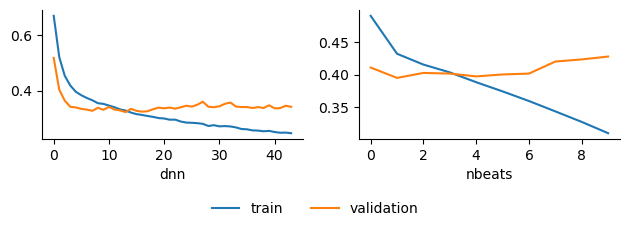

dnn test MAE: 23.06
nbeats test MAE: 23.23


In [6]:
import json
H = json.load(open(RES + 'training_hist.json'))
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.3))
for ax, k in zip(axs, ('dnn', 'nbeats')):
    h = np.array(H[k]); ax.plot(h[:, 0], label='train'); ax.plot(h[:, 1], label='validation'); ax.set_xlabel(k)
fig.legend(*axs[0].get_legend_handles_labels(), loc='lower center', ncol=2)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()
for k in ('dnn', 'nbeats'):
    print(k, 'test MAE:', round(float((F[k] - F.actual).abs().mean()), 2))

§ *Experiment yourself*: in `analysis_L13.py`, change `HID` or the recalibration frequency of the DNN and rerun.

## §4 Chronos-2 zero-shot: one week, then the full test year

In [7]:
try:
    import chronos
except ImportError:      # Google Colab
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'chronos-forecasting'], check=True)
import sys, torch
from chronos import BaseChronosPipeline
pipe = BaseChronosPipeline.from_pretrained('amazon/chronos-2', device_map=DEVICE)
s = x['RO'].loc[:'2026-10-31 23:00']
week = pd.date_range('2026-10-19', '2026-10-25')
ctx = [torch.tensor(s.loc[:str((d - pd.Timedelta(days=1)).date()) + ' 23:00'].values[-2048:], dtype=torch.float32) for d in week]
q, _ = pipe.predict_quantiles(ctx, prediction_length=24, quantile_levels=[0.1, 0.5, 0.9])
q = torch.stack([a.squeeze(0) for a in q]) if isinstance(q, list) else q
med = q[:, :, 1].cpu().numpy()
print('Chronos-2 MAE, week of 19 Oct 2026:', round(float(np.abs(med - RO.loc[week].values).mean()), 2))
mae = {m: round(float((F[m] - F.actual).abs().mean()), 2) for m in ['naive', 'lear', 'dnn', 'nbeats', 'bolt', 'timesfm', 'chronos2', 'chronos2_cov', 'ens']}
print(mae)

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Chronos-2 MAE, week of 19 Oct 2026: 26.48
{'naive': 27.74, 'lear': 22.79, 'dnn': 23.06, 'nbeats': 23.23, 'bolt': 21.67, 'timesfm': 22.37, 'chronos2': 20.72, 'chronos2_cov': 20.41, 'ens': 20.77}


## §5 Context length and covariates

In [8]:
print({c: round(float((F[f'chronos2_ctx{c}'] - F.actual).abs().mean()), 2) for c in (168, 512, 2048, 8192)})
print('with covariates:', round(float((F.chronos2_cov - F.actual).abs().mean()), 2))

{168: 24.45, 512: 21.34, 2048: 20.72, 8192: 20.95}
with covariates: 20.41


## §6 Diebold–Mariano test on daily losses

In [9]:
from scipy import stats
L1 = {m: (F[m] - F.actual).abs().groupby(F.date).sum().values for m in ['lear', 'dnn', 'chronos2', 'ens']}
def dm(a, b):
    d = L1[a] - L1[b]
    return round(float(1 - stats.norm.cdf(d.mean() / (d.std(ddof=1) / np.sqrt(len(d))))), 4)
print('p(Chronos-2 better than LEAR) =', dm('lear', 'chronos2'))
print('p(DNN better than LEAR) =', dm('lear', 'dnn'))

p(Chronos-2 better than LEAR) = 0.0
p(DNN better than LEAR) = 0.7606


## §7 Quantiles, pinball loss and split-conformal calibration

In [10]:
Q = pd.read_csv(RES + 'quantiles_hourly.csv', parse_dates=['date'])
W = lambda c: Q.pivot(index='date', columns='hour', values=c)
Yq = W('actual')
days = [d for d in Yq.index if d >= pd.Timestamp('2025-11-01') and Yq.loc[d].notna().all()]
lo, hi = W('ch2_q10'), W('ch2_q90')
score = np.maximum(lo - Yq, Yq - hi)
L_, H_ = [], []
for D in days:
    w = score.loc[D - pd.Timedelta(days=60):D - pd.Timedelta(days=1)].values.ravel(); w = w[~np.isnan(w)]
    qc = np.quantile(w, min(1, np.ceil((len(w) + 1) * 0.8) / len(w)))
    L_.append(lo.loc[D] - qc); H_.append(hi.loc[D] + qc)
y = Yq.loc[days].values
print('raw 80 % coverage:', round(100 * float(((y >= lo.loc[days].values) & (y <= hi.loc[days].values)).mean()), 1))
print('conformal 80 % coverage:', round(100 * float(((y >= np.array(L_)) & (y <= np.array(H_))).mean()), 1))

raw 80 % coverage: 76.5
conformal 80 % coverage: 79.3


## §8 Romanian load: foundation models against the seasonal naive

In [11]:
A = pd.read_csv(RES + 'load_actual.csv', index_col=0)
LF = pd.read_csv(RES + 'load_forecasts.csv', index_col=[0, 1])
for m in ['week', 'timesfm', 'chronos2']:
    print(m, 'MAPE %:', round(float(100 * np.abs((LF.loc[m].values - A.values) / A.values).mean()), 2))

week MAPE %: 7.15
timesfm MAPE %: 4.47
chronos2 MAPE %: 3.8


## §9 Value-at-Risk with Chronos-2 and a conformal shift

In [12]:
V = pd.read_csv(RES + 'var_SP500.csv', parse_dates=['date']).set_index('date')
def kupiec(h, a):
    n, k = len(h), int(h.sum()); p = k / n
    lr = -2 * ((n - k) * np.log(1 - a) + k * np.log(a) - (n - k) * np.log(1 - p) - k * np.log(p)) if k else -2 * n * np.log(1 - a)
    return round(float(1 - stats.chi2.cdf(lr, 1)), 3)
for m in ['hs', 'garch', 'ch', 'chc']:
    h = (V.r < V[m + '_01']).values
    print(m, 'violations:', int(h.sum()), 'expected:', round(0.01 * len(h), 1), 'Kupiec p:', kupiec(h, 0.01))

hs violations: 31 expected: 17.2 Kupiec p: 0.003
garch violations: 32 expected: 17.2 Kupiec p: 0.001
ch violations: 22 expected: 17.2 Kupiec p: 0.262
chc violations: 16 expected: 17.2 Kupiec p: 0.774
